# 演習9：paired準備とjoint-state準備を同条件で比較する

06のpaired準備（S₀とTを別々に圧縮し、分岐制御で組み合わせるA）と、
その出力状態を08の方法で直接圧縮するjoint準備を比較します。各条件で対応するA†も使います。

**既定はL=1・位相一周期の12点・各点1024 shotsです。**
両条件で同じ位相を走査し、準備と逆準備を比較します。両条件で同じM16発展、初期物理qubit配置、level 1、seed=7を使います。
配置はpaired回路の通常のtranspileから取得し、jointにも適用します。較正配置探索・DD・twirlingは追加しません。

| 量         | 共通設定                                               |
| ---------- | ------------------------------------------------------ |
| 分子・発展 | H₄/STO-3G/JW、R=2.0 Å、M16                             |
| 時間       | L=1、Δt=0.1、t=0.1 a.u.                                |
| 候補       | β∈[-π,π)の12点、ε=β/t                                  |
| shots      | 各条件・各点1024、合計24,576 shots                     |
| paired     | 06のM6準備をそのまま使用                               |
| joint      | pairedの出力を8層・32個の局所2-qubit unitaryへ直接圧縮 |
| 読出し     | 全9ビットが0の回数 / 実shots数                         |

理想確率・shot noiseのみ・FakeKawasaki・実機の各段階で両条件を並べます。
実機は両条件を1ジョブに含め、各候補のpaired/jointの順番を交互に入れ替えます。
実行順序や較正の変動を完全に制御する実験ではありません。
既定はfakeのみです。L=4を試す場合も設定セルから再実行し、両条件を同じLで比較してください。
位相は08と同じ一周期です。L=1ではエネルギー候補は約[-31.4,26.2] Haになります。
これは干渉信号を観測するための走査で、ギャップの推定区間や精度を意味しません。


In [28]:
# 初回だけ必要に応じてコメントを外して実行し、カーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"
# 実機モードのみ追加: %pip install "qiskit-ibm-runtime>=0.43,<0.44"


### データの取得先とキャッシュ

巨大な保存配列はNotebookへ埋め込みません。次セルは固定コミットから必要な回路・参照データを取得し、SHA-256を確認して再利用します。
リポジトリを取得済みなら、その中の固定データを優先します。なければローカルの `~/.cache/ftqc_handson/h4_pec_v1` へ保存します。
次セル先頭の `H4_CACHE_DIR` にパスを指定すると保存先を変えられます（環境変数 `H4_DATA_DIR` があればそちらが優先）。

Google Driveへ保存する場合は、先に別セルで次を実行し、その後 `H4_CACHE_DIR` を下記のパスに変更してください。

```python
from google.colab import drive
drive.mount('/content/drive')
# 次の初期化セルで指定:
# H4_CACHE_DIR = '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'
```

初回はネット接続が必要です。構造やMを変えたときは不足ファイルだけを取得し、既存ファイルは再ダウンロードしません。
オフラインで全選択肢を使う場合は、接続中に `download_h4_data()` で全20構造を事前取得します（約40 MiB）。
その後は `H4_OFFLINE=True` を選べます。補助コードも保存先の隣のruntimeフォルダへキャッシュします。
初期化セルは補助関数のため折り畳んであります。通常は先頭の設定だけを変更して実行してください。


In [29]:
H4_DATA_COMMIT = "4ab6ef3d06f4256b5c818feb8c3fa2af4381dd43"
# 保存先を指定する場合の例（Google Driveは先にmountする）:
# H4_CACHE_DIR = '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'
H4_CACHE_DIR = (
    None  # None: H4_DATA_DIR環境変数 → 取得済みリポジトリ → ユーザーキャッシュ
)
H4_OFFLINE = False  # True: ダウンロードせず、既存ファイルのみを使用

import os, json, hashlib, base64, tempfile
from pathlib import Path
from urllib.request import urlopen

SNAPSHOT_DIGEST = "6910f1f0aa7d0f2e43499683ba3a50f83db7aee09f3c64b07c91a6815ebdd4b3"
ASSET_DIGEST = SNAPSHOT_DIGEST
_H4_URL = f"https://raw.githubusercontent.com/QS-laboratory/IBM_handson/{H4_DATA_COMMIT}/hands_on/exercises/"
_H4_RUNTIME = {
    "h4_measurement.py": "d4dea4170f5e925599dcbbbc3b2c0ee7f2da1e25d7844ec024759e415c3a35f4",
    "h4_snapshot.py": "163691a0c005c844e0e449411c59eb5192218402df999c77056cbd7b223be997",
}


def snapshot_root():
    explicit = os.environ.get("H4_DATA_DIR") or H4_CACHE_DIR
    root = Path(explicit).expanduser().resolve() if explicit else None
    if root is None:
        for parent in [Path.cwd(), *Path.cwd().parents]:
            for candidate in [
                parent / "data/h4_pec_v1",
                parent / "hands_on/exercises/data/h4_pec_v1",
            ]:
                if (candidate / "manifest.json").is_file():
                    root = candidate
                    break
            if root is not None:
                break
    if root is None:
        root = Path.home() / ".cache/ftqc_handson/h4_pec_v1"
    if (
        str(root).startswith("/content/drive/MyDrive/")
        and not Path("/content/drive/MyDrive").is_dir()
    ):
        raise FileNotFoundError(
            '先に drive.mount("/content/drive") でGoogle Driveを接続してください'
        )
    manifest = root / "manifest.json"
    if (
        manifest.is_file()
        and hashlib.sha256(manifest.read_bytes()).hexdigest() != SNAPSHOT_DIGEST
    ):
        raise ValueError("Snapshot manifest differs from the pinned h4-pec-v1 manifest")
    return root


def _h4_fetch(path, url, digest):
    path = Path(path)
    if path.is_file():
        raw = path.read_bytes()
    else:
        if H4_OFFLINE:
            raise FileNotFoundError(
                f"Offline: missing {path}; pre-download the required data"
            )
        try:
            with urlopen(url, timeout=60) as response:
                raw = response.read()
        except Exception as exc:
            raise RuntimeError(
                f"H4データを取得できません: {path.name}. 接続またはH4_DATA_DIR/H4_CACHE_DIRを確認してください。"
            ) from exc
        if hashlib.sha256(raw).hexdigest() != digest:
            raise ValueError(f"Snapshot checksum mismatch: {path.name}")
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = None
        try:
            with tempfile.NamedTemporaryFile(dir=path.parent, delete=False) as stream:
                tmp = Path(stream.name)
                stream.write(raw)
            os.replace(tmp, path)
        finally:
            if tmp is not None:
                tmp.unlink(missing_ok=True)
    if hashlib.sha256(raw).hexdigest() != digest:
        raise ValueError(f"Snapshot checksum mismatch: {path.name}")
    return raw


def _h4_data(relative):
    digest = (
        SNAPSHOT_DIGEST
        if relative == "manifest.json"
        else SNAPSHOT_INDEX["files"][relative]
    )
    return _h4_fetch(
        snapshot_root() / relative, _H4_URL + "data/h4_pec_v1/" + relative, digest
    )


SNAPSHOT_INDEX = json.loads(_h4_data("manifest.json"))


class _H4Assets:
    """Read only the requested asset; no notebook-embedded binary strings."""

    def __init__(self, row):
        self.row = row

    def __getitem__(self, key):
        raw = _h4_data(self.row["id"] + "/" + self.row["assets"][key])
        return base64.b64encode(raw).decode()


def _h4_geometry(geometry):
    row = next((r for r in SNAPSHOT_INDEX["geometries"] if r["id"] == geometry), None)
    if row is None:
        raise ValueError("Unknown GEOMETRY; choose an ID from list_geometries()")
    cat = json.loads(_h4_data(geometry + "/catalog.json"))
    for name in ["preparation", "evolution"]:
        cat[name] = {int(k) if k != "exact" else k: v for k, v in cat[name].items()}
    return _H4Assets(row), cat, json.loads(_h4_data(geometry + "/provenance.json"))


ASSETS, CIRCUIT_CATALOG, PROVENANCE = _h4_geometry("R_2p00000000")
exec(
    compile(_h4_data("exact_preparation.py"), "h4_pec_v1/exact_preparation.py", "exec"),
    globals(),
)
_h4_cache_root = snapshot_root
for _name, _digest in _H4_RUNTIME.items():
    _local = snapshot_root().parent.parent / "tools" / _name
    _path = (
        _local
        if _local.is_file()
        else snapshot_root().parent
        / (snapshot_root().name + "_runtime")
        / H4_DATA_COMMIT
        / _name
    )
    exec(
        compile(_h4_fetch(_path, _H4_URL + "tools/" + _name, _digest), _name, "exec"),
        globals(),
    )
# The pinned runtime supplies measurement/inference helpers. Replace its eager
# snapshot reader with the verified, per-file cache above.
snapshot_geometry = _h4_geometry
snapshot_root = _h4_cache_root


def download_h4_data(
    geometries="all", prep_m=(4, 6, 8, "exact"), evolution_m=(8, 16, 32, "exact")
):
    """Optional prefetch for offline use. This never changes active circuits."""
    ids = (
        [r["id"] for r in SNAPSHOT_INDEX["geometries"]]
        if geometries == "all"
        else list(geometries)
    )
    count = 0
    for geometry in ids:
        row = next(
            (r for r in SNAPSHOT_INDEX["geometries"] if r["id"] == geometry), None
        )
        if row is None:
            raise ValueError("Unknown GEOMETRY")
        assets, cat, _ = _h4_geometry(geometry)
        keys = {"model"}
        for m in prep_m:
            keys.update(cat["preparation"][m]["keys"].values())
        for m in evolution_m:
            keys.add(cat["evolution"][m]["key"])
        for key in sorted(keys):
            assets[key]
            count += 1
    print(f"Cached {len(ids)} geometries / {count} assets in {snapshot_root()}")


print(
    "H4 data cache:",
    snapshot_root(),
    "— missing files are downloaded on demand; existing files are verified and reused.",
)

R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
H4 data cache: /Users/payashi/Documents/research/IBM_handson/hands_on/exercises/data/h4_pec_v1 — missing files are downloaded on demand; existing files are verified and reused.


## 0．比較条件・準備回路・shots数

L=1・位相一周期の12点を共通設定にします。元のM6準備はpairedとして保存し、
その実際の9-qubit出力を標的にjoint準備を学習します。
fidelityはpaired標的に対する値です。FCI状態に対する値ではありません。
08と同じSVD sweepを使う9-qubit dense状態の実装で、大規模MPS縮約ではありません。

以前のε∈[-4,4] HaではL=1の位相が±0.4 radに限られ、山の頂上しか観測できませんでした。
今回は位相範囲を固定し、振動の山と谷を観測します。shots/点・圧縮・配置・ノイズモデルは同じ条件です。


### joint圧縮と信号診断の補助関数

08の圧縮を再利用します。配置探索・DD・twirlingは追加しません。


In [30]:
CHAIN = (8, 0, 1, 2, 3, 4, 5, 6, 7)


def joint_mps(target, chi=16):
    """TT-SVD of the nine-qubit joint state in ancilla-first chain order."""
    target = np.asarray(target, complex)
    if target.shape != (512,) or not np.isclose(np.linalg.norm(target), 1):
        raise ValueError("A normalized nine-qubit joint target is required")
    if not isinstance(chi, int) or isinstance(chi, bool) or chi < 1:
        raise ValueError("chi must be a positive integer")
    axes = [8 - q for q in CHAIN]
    tensor = target.reshape([2] * 9).transpose(axes)
    cores, rank = [], 1
    for _ in range(8):
        u, s, vh = np.linalg.svd(tensor.reshape(rank * 2, -1), full_matrices=False)
        keep = min(chi, len(s))
        cores.append(u[:, :keep].reshape(rank, 2, keep))
        tensor = s[:keep, None] * vh[:keep]
        rank = keep
    cores.append(tensor.reshape(rank, 2, 1))
    rebuilt = cores[0][0]
    for core in cores[1:]:
        rebuilt = np.tensordot(rebuilt, core, axes=(-1, 0))
    state = rebuilt[..., 0].transpose(np.argsort(axes)).reshape(-1)
    retained = float(np.linalg.norm(state) ** 2)
    state /= np.sqrt(retained)
    return cores, state, retained


def two_site_view(state, pair):
    # Qiskit's two-qubit matrix basis is |q_second q_first>.
    a, b = pair
    axes = [8 - b, 8 - a] + [i for i in range(9) if i not in (8 - b, 8 - a)]
    return state.reshape([2] * 9).transpose(axes).reshape(4, -1), axes


def apply_two(state, gate, pair):
    matrix, axes = two_site_view(state, pair)
    return (gate @ matrix).reshape([2] * 9).transpose(np.argsort(axes)).reshape(-1)


def initial_joint_state():
    # A product determinant times |+>_ancilla, prepared without controlled gates.
    state = np.zeros(512, complex)
    state[165] = state[165 + 256] = 1 / np.sqrt(2)
    return state


def compress_joint(target, layers=8, sweeps=2000, seeds=(3, 17, 42), chi=16):
    if layers < 1 or sweeps < 1 or not seeds:
        raise ValueError("Positive layers/sweeps and at least one seed are required")
    cores, mps_target, retained = joint_mps(target, chi)
    pairs = [
        (CHAIN[j], CHAIN[j + 1])
        for layer in range(layers)
        for j in range(layer % 2, 8, 2)
    ]
    best, runs = None, []
    for seed in seeds:
        rng = np.random.default_rng(seed)
        gates = []
        for _ in pairs:
            z = np.eye(4) + 0.05 * (
                rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4))
            )
            u, _, vh = np.linalg.svd(z)
            gates.append(u @ vh)
        history = []
        for sweep in range(sweeps):
            if sweep % 2 == 0:
                suffix = [None] * (len(gates) + 1)
                suffix[-1] = mps_target
                for j in reversed(range(len(gates))):
                    suffix[j] = apply_two(suffix[j + 1], gates[j].conj().T, pairs[j])
                state = initial_joint_state()
                for j, pair in enumerate(pairs):
                    x, _ = two_site_view(state, pair)
                    y, _ = two_site_view(suffix[j + 1], pair)
                    u, _, vh = np.linalg.svd(y @ x.conj().T)
                    gates[j] = u @ vh
                    state = apply_two(state, gates[j], pair)
            else:
                prefix = [initial_joint_state()]
                for gate, pair in zip(gates, pairs):
                    prefix.append(apply_two(prefix[-1], gate, pair))
                state = mps_target.copy()
                for j in reversed(range(len(gates))):
                    x, _ = two_site_view(prefix[j], pairs[j])
                    y, _ = two_site_view(state, pairs[j])
                    u, _, vh = np.linalg.svd(y @ x.conj().T)
                    gates[j] = u @ vh
                    state = apply_two(state, gates[j].conj().T, pairs[j])
            prepared = initial_joint_state()
            for gate, pair in zip(gates, pairs):
                prepared = apply_two(prepared, gate, pair)
            history.append(float(abs(np.vdot(mps_target, prepared)) ** 2))
        fidelity = float(abs(np.vdot(target, prepared)) ** 2)
        runs.append(dict(seed=seed, fidelity=fidelity, history=history))
        print(f"Joint compression: seed={seed}, fidelity={fidelity:.8f}", flush=True)
        if best is None or fidelity > best["fidelity"]:
            best = dict(fidelity=fidelity, gates=np.array(gates), seed=seed)
    circuit = QuantumCircuit(9, name="joint_MPS_compressed")
    for q in (0, 2, 5, 7):
        circuit.x(q)
    circuit.h(8)
    for gate, pair in zip(best["gates"], pairs):
        circuit.unitary(gate, list(pair))
    actual = Statevector.from_instruction(circuit).data
    np.testing.assert_allclose(
        abs(np.vdot(target, actual)) ** 2, best["fidelity"], atol=1e-11
    )
    fingerprint = hashlib.sha256(
        best["gates"].tobytes() + np.array(pairs).tobytes()
    ).hexdigest()
    report = dict(
        layers=layers,
        sweeps=sweeps,
        seeds=list(seeds),
        selected_seed=best["seed"],
        chi=chi,
        bond_dimensions=[c.shape[2] for c in cores[:-1]],
        mps_retained_norm_squared=retained,
        fidelity=best["fidelity"],
        circuit_digest=fingerprint,
        two_qubit_blocks=len(pairs),
        runs=runs,
    )
    return circuit, report


def wilson_interval(k, n, z=1.959963984540054):
    k, n = np.asarray(k, float), np.asarray(n, float)
    if np.any(n <= 0) or np.any(k < 0) or np.any(k > n):
        raise ValueError("0 <= counts <= positive shots が必要です")
    p = k / n
    denominator = 1 + z * z / n
    center = (p + z * z / (2 * n)) / denominator
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denominator
    return np.maximum(0, center - half), np.minimum(1, center + half)


def summarize_scan(beta, k, n, seed=42, simulations=4999):
    beta = np.asarray(beta, float)
    k, n = np.asarray(k), np.asarray(n)
    if (
        beta.ndim != 1
        or len(beta) < 3
        or k.shape != beta.shape
        or n.shape != beta.shape
        or not np.all(np.isfinite(beta))
        or not np.issubdtype(k.dtype, np.integer)
        or not np.issubdtype(n.dtype, np.integer)
        or np.any(n <= 0)
        or np.any(k < 0)
        or np.any(k > n)
    ):
        raise ValueError("位相と整数counts/shotsの配列を確認してください")
    basis = np.column_stack([np.cos(beta), np.sin(beta)])
    design = np.column_stack([np.ones(len(beta)), basis])
    if np.linalg.matrix_rank(design) != 3:
        raise ValueError("位相点が干渉曲線を決定できません")
    coefficients = np.linalg.lstsq(
        design * np.sqrt(n[:, None]), k / np.sqrt(n), rcond=None
    )[0]
    low, high = wilson_interval(k, n)
    total, trials = int(k.sum()), int(n.sum())
    pooled = total / trials
    centered = basis - np.average(basis, axis=0, weights=n)
    metric = np.linalg.pinv(centered.T @ (n[:, None] * centered))
    score = (k - n * pooled) @ centered
    statistic = float(score @ metric @ score)
    if total == 0 or total == trials:
        pvalue = 1.0
    else:
        null_k = np.random.default_rng(seed).multivariate_hypergeometric(
            n, total, size=simulations
        )
        null_scores = (null_k - n * pooled) @ centered
        null_stats = np.einsum("bi,ij,bj->b", null_scores, metric, null_scores)
        pvalue = float(
            (1 + np.count_nonzero(null_stats >= statistic - 1e-14)) / (simulations + 1)
        )
    return dict(
        beta=beta.tolist(),
        counts_all_zero=k.tolist(),
        actual_shots=n.tolist(),
        observed=(k / n).tolist(),
        lower_95=low.tolist(),
        upper_95=high.tolist(),
        coefficients=coefficients.tolist(),
        amplitude=float(np.hypot(*coefficients[1:])),
        constant_probability=pooled,
        statistic=statistic,
        p_value=pvalue,
        monte_carlo_samples=simulations,
    )


def native_joint_preparation(original):
    """Preserve small Weyl components when lowering the trained joint circuit."""
    from qiskit.circuit.library import CXGate
    from qiskit.synthesis import TwoQubitBasisDecomposer, TwoQubitWeylDecomposition

    decomposer = TwoQubitBasisDecomposer(CXGate())
    native = QuantumCircuit(9)
    native.global_phase = original.global_phase
    for item in original.data:
        qubits = [original.find_bit(q).index for q in item.qubits]
        if item.operation.num_qubits == 1:
            native.append(item.operation, qubits)
            continue
        u = Operator(item.operation).data
        local = decomposer(u, approximate=False)
        if np.max(abs(Operator(local).data - u)) > 1e-10:
            # Same checked 3-CX construction as the pinned H4 catalog builder.
            # The private decomposition is used only with the pinned Qiskit 2.4.1.
            weyl = TwoQubitWeylDecomposition(u, fidelity=None)
            parts = decomposer.decomp3_supercontrolled(weyl._inner_decomposition)
            local = QuantumCircuit(2)
            for j in range(4):
                local.unitary(parts[2 * j], [0])
                local.unitary(parts[2 * j + 1], [1])
                if j < 3:
                    local.cx(0, 1)
            local.global_phase += np.angle(np.vdot(Operator(local).data, u))
        np.testing.assert_allclose(Operator(local).data, u, atol=1e-10, rtol=0)
        native.compose(local, qubits, inplace=True)
    native = transpile(
        native,
        basis_gates=["rz", "sx", "x", "cx"],
        optimization_level=1,
        seed_transpiler=7,
        approximation_degree=1.0,
    )
    reference = Statevector.from_instruction(original).data
    actual = Statevector.from_instruction(native).data
    np.testing.assert_allclose(
        abs(np.vdot(reference, actual)) ** 2, 1.0, atol=1e-10, rtol=0
    )
    return native


In [31]:
SHOTS = 1024
L = 1  # paired/jointの両条件に共通。06と同じ時間を試す場合は4
PHASE_POINTS = 12  # 一周期を重複なしで測る
JOINT_LAYERS = 8
JOINT_SWEEPS = 2000
JOINT_SEEDS = (3, 17, 42)
for name, value in [("SHOTS", SHOTS), ("L", L), ("PHASE_POINTS", PHASE_POINTS)]:
    if not isinstance(value, int) or isinstance(value, bool) or value < 1:
        raise ValueError(f"{name}は正の整数を指定してください")
if PHASE_POINTS < 3:
    raise ValueError("PHASE_POINTSは3以上を指定してください")
TIME = L * DT
BETA = np.linspace(-np.pi, np.pi, PHASE_POINTS, endpoint=False)
TRIAL_GAPS = BETA / TIME  # Lを変えても同じ一周期を測る

select_geometry("R_2p00000000")
select_circuits(6, 16)
BASELINE_DIGEST = CIRCUIT_DIGEST
A_PAIRED = A_APPROX.copy()  # 06の準備を保持する
JOINT_TARGET = Statevector.from_instruction(A_PAIRED).data
A_JOINT, JOINT_REPORT = compress_joint(
    JOINT_TARGET, layers=JOINT_LAYERS, sweeps=JOINT_SWEEPS, seeds=JOINT_SEEDS, chi=16
)
if JOINT_REPORT["fidelity"] < 0.99:
    raise ValueError("Joint fidelityが0.99未満です。sweepsまたは層数を増やしてください")
A_JOINT = native_joint_preparation(A_JOINT)
PREPARATIONS = dict(paired=A_PAIRED, joint=A_JOINT)
PREP_STATES = {
    arm: Statevector.from_instruction(a).data for arm, a in PREPARATIONS.items()
}
np.testing.assert_allclose(
    abs(np.vdot(JOINT_TARGET, PREP_STATES["joint"])) ** 2,
    JOINT_REPORT["fidelity"],
    atol=1e-10,
    rtol=0,
)
PREP_DIGESTS = dict(
    paired=BASELINE_DIGEST,
    joint=hashlib.sha256(
        (
            BASELINE_DIGEST
            + JOINT_REPORT["circuit_digest"]
            + "09-joint-native-v2-exact"
        ).encode()
    ).hexdigest(),
)
COMPARISON_DIGEST = hashlib.sha256(
    json.dumps(PREP_DIGESTS, sort_keys=True).encode()
).hexdigest()
_RETURN_CACHE = {}


def preparation_probability(arm, length, trial_gaps):
    if arm not in PREPARATIONS:
        raise ValueError("arm must be paired or joint")
    if (
        not isinstance(length, (int, np.integer))
        or isinstance(length, (bool, np.bool_))
        or length < 1
    ):
        raise ValueError("length must be a positive integer")
    key = (arm, int(length))
    if key not in _RETURN_CACHE:
        u = np.linalg.matrix_power(U_APPROX, int(length))
        state = PREP_STATES[arm]
        _RETURN_CACHE[key] = [
            np.vdot(branch, u @ branch) for branch in (state[:256], state[256:])
        ]
    a, b = _RETURN_CACHE[key]
    return np.clip(
        abs(a + np.exp(1j * np.asarray(trial_gaps) * length * DT) * b) ** 2, 0, 1
    )


def preparation_circuit(arm, length, trial_gap):
    # Both arms use the same saved evolution and the inverse of their own preparation.
    if arm not in PREPARATIONS:
        raise ValueError("arm must be paired or joint")
    if (
        not isinstance(length, (int, np.integer))
        or isinstance(length, (bool, np.bool_))
        or length < 1
    ):
        raise ValueError("length must be a positive integer")
    circuit = QuantumCircuit(9)
    circuit.compose(PREPARATIONS[arm], inplace=True)
    for _ in range(int(length)):
        circuit.compose(EVOLUTION_APPROX, range(8), inplace=True)
    circuit.p(trial_gap * length * DT, 8)
    circuit.compose(PREPARATIONS[arm].inverse(), inplace=True)
    return circuit


path = Path("outputs/exercise9")
path.mkdir(parents=True, exist_ok=True)
(path / "joint_compression.json").write_text(json.dumps(JOINT_REPORT, indent=2))
with (path / "paired_joint_preparations.qpy").open("wb") as stream:
    qpy.dump(list(PREPARATIONS.values()), stream)
print("Joint fidelity to paired target:", JOINT_REPORT["fidelity"])
print("L:", L, "time:", TIME, "phase points:", PHASE_POINTS)
print("beta / rad:", BETA)
print("trial gaps / Ha:", TRIAL_GAPS)
print(
    "Shots per arm:",
    len(TRIAL_GAPS) * SHOTS,
    "total:",
    len(PREPARATIONS) * len(TRIAL_GAPS) * SHOTS,
)
for arm, a in PREPARATIONS.items():
    print(
        arm,
        "serial CX (A + A† + evolution):",
        2 * int(a.count_ops().get("cx", 0)) + L * SERIAL_CX["evolution"],
    )
print("FCI gap for checking only / Ha:", GAP)


R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
Joint compression: seed=3, fidelity=0.99583502
Joint compression: seed=17, fidelity=0.99661594
Joint compression: seed=42, fidelity=0.99767574
Joint fidelity to paired target: 0.9976757425611849
L: 1 time: 0.1 phase points: 12
beta / rad: [-3.14159265 -2.61799388 -2.0943951  -1.57079633 -1.04719755 -0.52359878
  0.          0.52359878  1.04719755  1.57079633  2.0943951   2.61799388]
trial gaps / Ha: [-31.41592654 -26.17993878 -20.94395102 -15.70796327 -10.47197551
  -5.23598776   0.           5.23598776  10.47197551  15.70796327
  20.94395102  26.17993878]
Shots per arm: 12288 total: 24576
paired serial CX (A + A† + evolution): 732
joint serial CX (A + A† + evolution): 408
FCI gap for checking only / Ha: 0.015904957916185403


## 1．同じ干渉回路の準備と逆準備を比較する

```text
a=q8 : |0> ──┌────────┐────────P(β)──┌────────┐──M──┐
             │ A_arm  │              │ A_arm† │     ├─ 全0回数 / 実shots
s=q0..7: ────└────────┘──[U]^L────────└────────┘──M──┘
```

armはpairedまたはjointです。実際の準備状態を
$|\Phi\rangle=|0\rangle|\phi_0\rangle+|1\rangle|\phi_1\rangle$ とすると、
$P(0^9|\beta)=|\langle\phi_0|U^L|\phi_0\rangle+e^{i\beta}\langle\phi_1|U^L|\phi_1\rangle|^2$ です。
分岐の重みを含め、各armのstatevectorから確率を計算します。
06のGaussian更新に代えて、両条件の理想確率・counts・位相依存性を直接比較します。


### 比較結果の保存・描画

countsを先に保存し、両条件を同じ軸で表示します。p値は各条件の信号検出であり、条件間の優劣の検定ではありません。


In [ ]:
def comparison_settings():
    return dict(
        comparison_digest=COMPARISON_DIGEST,
        geometry=SELECTED_GEOMETRY,
        evolution_m=SELECTED_EVOLUTION_M,
        preparation_digests=PREP_DIGESTS,
        L=L,
        time=TIME,
        scan="full_period",
        phases=BETA.tolist(),
        trial_gaps=TRIAL_GAPS.tolist(),
        shots=SHOTS,
        optimization_level=1,
        seed_transpiler=7,
    )


def atomic_comparison_json(path, record):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="w", dir=path.parent, delete=False) as stream:
        temporary = Path(stream.name)
        json.dump(record, stream, indent=2)
    os.replace(temporary, path)


def analyze_comparison(record):
    spec = record["specification"]
    schedule, raw = spec["schedule"], record["counts"]
    if len(raw) != len(schedule):
        raise ValueError("Incomplete paired/joint counts")
    arms = {}
    for arm in PREPARATIONS:
        entries = sorted(
            [(s["point"], c) for s, c in zip(schedule, raw) if s["arm"] == arm],
            key=lambda item: item[0],
        )
        if [point for point, _ in entries] != list(range(len(spec["trial_gaps"]))):
            raise ValueError("Missing or duplicate scan points")
        counts = [c for _, c in entries]
        if any(
            not c
            or any(
                len(bits) != 9
                or set(bits) - set("01")
                or not isinstance(k, int)
                or k < 0
                for bits, k in c.items()
            )
            for c in counts
        ):
            raise ValueError("Invalid nine-bit counts")
        k = np.array([c.get("0" * 9, 0) for c in counts], dtype=int)
        shots = np.array([sum(c.values()) for c in counts], dtype=int)
        beta = np.asarray(spec["trial_gaps"]) * spec["time"]
        signal = summarize_scan(beta, k, shots, seed=42)
        signal["p_value_adjusted"] = min(1.0, len(PREPARATIONS) * signal["p_value"])
        signal["detected"] = signal["p_value_adjusted"] < 0.05
        arms[arm] = signal
    record["analysis"] = arms
    return arms


def plot_comparison(record, title):
    spec = record["specification"]
    if spec["comparison_digest"] != COMPARISON_DIGEST:
        raise ValueError("結果と現在の準備回路が異なります")
    arms = record.get("analysis") or analyze_comparison(record)
    gaps = np.asarray(spec["trial_gaps"])
    beta = gaps * spec["time"]
    dense_beta = (
        np.linspace(-np.pi, np.pi, 501)
        if spec.get("scan") == "full_period"
        else np.linspace(beta[0], beta[-1], 501)
    )
    dense = dense_beta / spec["time"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    upper = 1 / 512
    for color, (arm, signal) in zip(("C0", "C1"), arms.items()):
        y = np.asarray(signal["observed"])
        low, high = np.asarray(signal["lower_95"]), np.asarray(signal["upper_95"])
        upper = max(upper, float(high.max()))
        for ax in axes:
            ax.errorbar(
                beta,
                y,
                yerr=np.maximum(0, [y - low, high - y]),
                fmt="o",
                capsize=3,
                color=color,
                label=arm + " / 95% CI",
            )
        axes[0].plot(
            dense_beta,
            preparation_probability(arm, spec["L"], dense),
            "--",
            color=color,
            label=arm + " noiseless",
        )
        c, a, b = signal["coefficients"]
        axes[1].plot(
            dense_beta,
            c + a * np.cos(dense_beta) + b * np.sin(dense_beta),
            color=color,
            label=arm + " harmonic projection",
        )
    for ax in axes:
        ax.axhline(1 / 512, color="gray", ls=":", label="Uniform 9-bit reference")
        ax.set(xlabel="Correction phase beta / rad", ylabel="P(all zero) or frequency")
        ax.legend(fontsize=7)
    axes[0].set(ylim=(-0.02, 1.02), title="Counts and ideal circuits")
    axes[1].set(ylim=(0, upper * 1.15), title="Counts (zoom)")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    print(
        "arm | all-zero / total shots | harmonic amplitude | adjusted p | signal | depth | 2q gates"
    )
    for arm, signal in arms.items():
        resources = [r for r in spec.get("resources", []) if r["arm"] == arm]
        depth = max((r["depth"] for r in resources), default="—")
        gates = max((r["two_qubit_gates"] for r in resources), default="—")
        print(
            f"{arm} | {sum(signal['counts_all_zero'])}/{sum(signal['actual_shots'])} | "
            f"{signal['amplitude']:.6g} | {signal['p_value_adjusted']:.4g} | "
            f"{'detected' if signal['detected'] else 'unresolved'} | {depth} | {gates}"
        )


## 2．shot noiseなし：両条件の理想信号

近似圧縮による信号自体の差を確認し、各候補を実際の9-qubit回路と照合します。


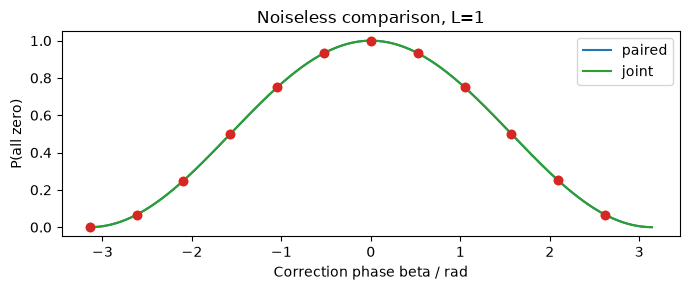

Maximum ideal difference: 0.00012881049077506646


In [ ]:
ideal_comparison = {}
fig, ax = plt.subplots(figsize=(7, 3))
dense_beta = np.linspace(-np.pi, np.pi, 501)
dense = dense_beta / TIME
for arm in PREPARATIONS:
    values = preparation_probability(arm, L, TRIAL_GAPS)
    ideal_comparison[arm] = values.tolist()
    for gap, expected in zip(TRIAL_GAPS, values):
        actual = (
            abs(
                Statevector.from_instruction(
                    preparation_circuit(arm, L, float(gap))
                ).data[0]
            )
            ** 2
        )
        np.testing.assert_allclose(actual, expected, atol=1e-10, rtol=0)
    ax.plot(dense_beta, preparation_probability(arm, L, dense), label=arm)
    ax.plot(BETA, values, "o")
ax.set(
    xlabel="Correction phase beta / rad",
    ylabel="P(all zero)",
    title=f"Noiseless comparison, L={L}",
)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)
atomic_comparison_json(
    "outputs/exercise9/ideal_comparison.json",
    dict(settings=comparison_settings(), probabilities=ideal_comparison),
)
print(
    "Maximum ideal difference:",
    np.max(abs(np.asarray(ideal_comparison["paired"]) - ideal_comparison["joint"])),
)


## 3．shot noiseのみ：両条件に同じshots数

ゲートノイズなしの二項乱数です。各条件・各点に共通のshots数を割り当てます。


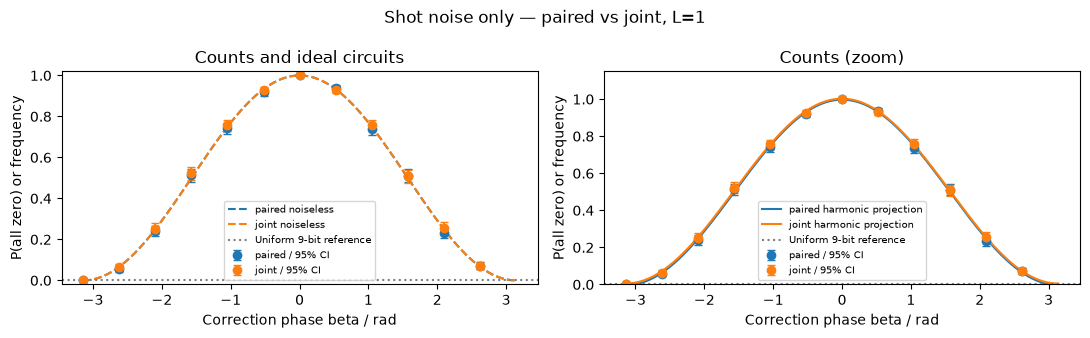

arm | all-zero / total shots | harmonic amplitude | adjusted p | signal | depth | 2q gates
paired | 6105/12288 | 0.500402 | 0.0004 | detected | — | —
joint | 6191/12288 | 0.498748 | 0.0004 | detected | — | —


In [34]:
rng = np.random.default_rng(42)
schedule, raw = [], []
for point, gap in enumerate(TRIAL_GAPS):
    for arm in PREPARATIONS:
        k = int(rng.binomial(SHOTS, preparation_probability(arm, L, [gap])[0]))
        schedule.append(dict(arm=arm, point=point))
        raw.append({"000000000": k, "000000001": SHOTS - k})
# 二項試行で生成した全0以外の回数は、この参考セルでは一つのラベルへ集約。
shot_comparison = dict(
    source="binomial_all_zero_only",
    specification=dict(comparison_settings(), schedule=schedule),
    counts=raw,
)
shot_path = Path("outputs/exercise9/shot_comparison.json")
atomic_comparison_json(shot_path, shot_comparison)
analyze_comparison(shot_comparison)
atomic_comparison_json(shot_path, shot_comparison)
plot_comparison(shot_comparison, f"Shot noise only — paired vs joint, L={L}")


## 3a．FakeKawasaki：同じ配置・shotsで比較する

06と同じFakeKawasaki＋Aerのゲート・読出しノイズです。明示的idle緩和は追加しません。
このfakeは過去の127-qubit/ECR装置情報で、現在の実機の較正とは異なります。
pairedの通常のlevel 1配置をjointにも適用し、ルーティング後の費用とcountsを比較します。
位相はパラメータとしてtranspileし、同じarmの全候補で同じ配置とゲート構造を使います。

各候補でpaired/jointを交互の順番に並べ、両条件の全countsを保存します。
p値は一定確率に対する位相依存性を調べ、2条件分のBonferroni補正後p<0.05を表示します。
これは条件間の優劣の検定やギャップ精度の保証ではありません。
`USE_FAKE_KAWASAKI=True` の間はIBM接続と送信をスキップします。


In [35]:
# FakeKawasakiを初めて使う場合は、この行を有効にして実行し、カーネルを再起動してください。
# %pip install "qiskit-ibm-runtime>=0.43,<0.44" "qiskit-aer>=0.17,<0.18"
USE_FAKE_KAWASAKI = True  # True: ローカルのノイズ付き模擬Kawasakiを使う


In [36]:
def compile_preparation_comparison(backend):
    from qiskit.circuit import Parameter

    beta = Parameter("comparison_beta")
    templates = {}
    common_layout = None
    for arm in PREPARATIONS:
        logical = preparation_circuit(arm, L, beta / TIME)
        logical.measure_all()
        options = {} if common_layout is None else dict(initial_layout=common_layout)
        templates[arm] = transpile(
            logical,
            backend=backend,
            optimization_level=1,
            seed_transpiler=7,
            num_processes=1,
            approximation_degree=1.0,
            **options,
        )
        layout = templates[arm].layout.initial_index_layout(filter_ancillas=True)
        if common_layout is None:
            common_layout = layout
        if layout != common_layout:
            raise ValueError("Both arms must use the same initial physical layout")
    circuits, schedule, resources = [], [], []
    for point, gap in enumerate(TRIAL_GAPS):
        order = ("paired", "joint") if point % 2 == 0 else ("joint", "paired")
        for arm in order:
            isa = templates[arm].assign_parameters({beta: float(gap * TIME)})
            circuits.append(isa)
            schedule.append(dict(arm=arm, point=point))
            resources.append(
                dict(
                    arm=arm,
                    point=point,
                    depth=isa.depth(),
                    two_qubit_gates=sum(
                        item.operation.num_qubits == 2 for item in isa.data
                    ),
                    operations=dict(isa.count_ops()),
                    initial_layout=isa.layout.initial_index_layout(
                        filter_ancillas=True
                    ),
                    final_layout=isa.layout.final_index_layout(filter_ancillas=True),
                )
            )
    properties = backend.properties()
    # QPY contains generated circuit names/UUIDs; hash bound operations instead
    # so an identical preview in a fresh kernel can retrieve the saved job.
    signatures = [
        dict(
            global_phase=float(c.global_phase),
            operations=[
                [
                    item.operation.name,
                    [float(p) for p in item.operation.params],
                    [c.find_bit(q).index for q in item.qubits],
                    [c.find_bit(bit).index for bit in item.clbits],
                ]
                for item in c.data
            ],
        )
        for c in circuits
    ]
    spec = dict(
        comparison_settings(),
        backend=backend.name,
        num_qubits=backend.num_qubits,
        calibration_last_update=properties.last_update_date.isoformat(),
        initial_layout=common_layout,
        schedule=schedule,
        resources=resources,
        isa_sha256=hashlib.sha256(
            json.dumps(signatures, sort_keys=True).encode()
        ).hexdigest(),
    )
    print("Shared initial layout:", common_layout)
    for arm in PREPARATIONS:
        report = next(r for r in resources if r["arm"] == arm)
        print(
            arm, "depth:", report["depth"], "2-qubit gates:", report["two_qubit_gates"]
        )
    print(
        f"{len(circuits)} circuits × {SHOTS} shots = {len(circuits) * SHOTS} requested shots"
    )
    return dict(specification=spec, circuits=circuits)


def fake_kawasaki_comparison(shots, seed=42):
    if shots != SHOTS:
        raise ValueError("設定セルのSHOTSを使ってください")
    from qiskit_aer import AerSimulator
    from qiskit_ibm_runtime.fake_provider import FakeKawasaki

    fake_backend = FakeKawasaki()
    preview = compile_preparation_comparison(fake_backend)
    simulator = AerSimulator.from_backend(
        fake_backend,
        method="density_matrix",
        enable_truncation=True,
        max_parallel_experiments=1,
        max_parallel_threads=4,
    )
    if (
        simulator.options.noise_model is None
        or simulator.options.noise_model.is_ideal()
    ):
        raise RuntimeError("FakeKawasaki noise model is missing")
    result = simulator.run(
        preview["circuits"], shots=shots, seed_simulator=seed
    ).result()
    if not result.success:
        raise RuntimeError(f"Aer failed: {result.status}")
    return dict(
        source="fake_kawasaki_paired_joint_counts",
        specification=preview["specification"],
        noise_model_is_ideal=False,
        seed_simulator=seed,
        snapshot_sha256={
            name: hashlib.sha256(
                (Path(fake_backend.dirname) / name).read_bytes()
            ).hexdigest()
            for name in (fake_backend.conf_filename, fake_backend.props_filename)
        },
        counts=[dict(result.get_counts(j)) for j in range(len(preview["circuits"]))],
    )


def acquire_ibm_comparison(
    preview, service, backend, instance="", directory="outputs/exercise9/ibm_jobs"
):
    if preview is None or service is None or backend is None:
        raise RuntimeError("先にIBM接続と両条件のプレビューを実行してください")
    spec = preview["specification"]
    if (
        any(spec.get(key) != value for key, value in comparison_settings().items())
        or spec["backend"] != backend.name
    ):
        raise ValueError("Settings changed; rerun the preview")
    spec = dict(spec, instance_sha256=hashlib.sha256(instance.encode()).hexdigest())
    key = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
    path = Path(directory) / (key + ".json")
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        record = json.loads(path.read_text())
        if record["specification"] != spec:
            raise ValueError("Stored specification differs")
        if "counts" in record:
            return record, path
        if "job_id" not in record:
            raise RuntimeError(
                f"Interrupted submission: inspect IBM jobs before recovery: {path}"
            )
        job = service.job(record["job_id"])
    else:
        from qiskit_ibm_runtime import SamplerV2

        with path.with_suffix(".qpy").open("wb") as stream:
            qpy.dump(preview["circuits"], stream)
        record = dict(source="ibm_paired_joint_submission", specification=spec)
        with path.open("x") as stream:
            json.dump(record, stream, indent=2)
        # Keep additional runtime suppression disabled for both arms.
        options = dict(
            dynamical_decoupling=dict(enable=False),
            twirling=dict(enable_gates=False, enable_measure=False),
        )
        job = SamplerV2(mode=backend, options=options).run(
            preview["circuits"], shots=spec["shots"]
        )
        record["job_id"] = job.job_id()
        atomic_comparison_json(path, record)
        print("Saved job ID:", record["job_id"], "in", path, flush=True)
    record.update(
        source="ibm_paired_joint_counts",
        counts=[dict(pub.data.meas.get_counts()) for pub in job.result()],
    )
    # Preserve raw data before analysis or plotting.
    atomic_comparison_json(path, record)
    return record, path


Shared initial layout: [120, 119, 118, 117, 116, 115, 114, 109, 121]
paired depth: 2611 2-qubit gates: 1260
joint depth: 669 2-qubit gates: 408
24 circuits × 1024 shots = 24576 requested shots
Saved raw counts: outputs/exercise9/fake_paired_joint_full_phase_L1.json


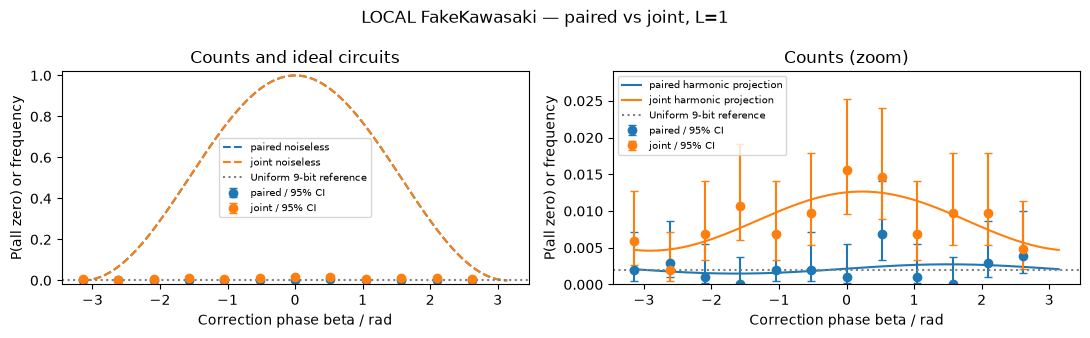

arm | all-zero / total shots | harmonic amplitude | adjusted p | signal | depth | 2q gates
paired | 26/12288 | 0.000630368 | 1 | unresolved | 2611 | 1260
joint | 106/12288 | 0.00402513 | 0.0088 | detected | 669 | 408


In [37]:
fake_comparison_record = None
if USE_FAKE_KAWASAKI:
    fake_comparison_record = fake_kawasaki_comparison(SHOTS, seed=42)
    fake_path = Path(f"outputs/exercise9/fake_paired_joint_full_phase_L{L}.json")
    atomic_comparison_json(fake_path, fake_comparison_record)
    print("Saved raw counts:", fake_path)
    analyze_comparison(fake_comparison_record)
    atomic_comparison_json(fake_path, fake_comparison_record)
    plot_comparison(
        fake_comparison_record, f"LOCAL FakeKawasaki — paired vs joint, L={L}"
    )
else:
    print("FakeKawasakiをスキップしました。")


## IBM Quantum接続準備（実機を使う方のみ）

実機を使う場合は、先に `USE_FAKE_KAWASAKI=False` にし、次セルを `USE_IBM=True` にします。
CRN・本人のAPIキー・backendを入力してください。このセルでは送信しません。
その後のプレビューを確認し、最後に `RUN_HARDWARE=True` にしてください。


In [ ]:
USE_IBM = True  # 実機を使う方のみ True に変更
IBM_SERVICE = None
IBM_INSTANCE = ""
IBM_BACKEND_NAME = ""

if USE_IBM and not globals().get("USE_FAKE_KAWASAKI", False):
    import subprocess
    import sys
    from getpass import getpass

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "qiskit==2.4.1",
            "qiskit-ibm-runtime>=0.43,<0.44",
        ]
    )
    from qiskit_ibm_runtime import QiskitRuntimeService

    IBM_INSTANCE = input("今回使うインスタンスのCRN：").strip()
    if not IBM_INSTANCE.startswith("crn:"):
        raise ValueError("インスタンスのCRN（crn:で始まる文字列）を入力してください")
    _api_key = getpass("本人のAPIキー（非表示）：").strip()
    try:
        IBM_SERVICE = QiskitRuntimeService(
            channel="ibm_quantum_platform",
            token=_api_key,
            instance=IBM_INSTANCE,
        )
    finally:
        del _api_key

    _backend_names = sorted(b.name for b in IBM_SERVICE.backends())
    print("利用可能なバックエンド：", ", ".join(_backend_names))
    if not _backend_names:
        raise RuntimeError("利用可能な実機がありません。主催者へお知らせください")
    IBM_BACKEND_NAME = input("一覧から今回使うバックエンド名を入力：").strip()
    if IBM_BACKEND_NAME not in _backend_names:
        raise ValueError(
            "一覧にあるバックエンド名を入力し、このセルを再実行してください"
        )
    print("接続確認完了：", IBM_BACKEND_NAME, "（ジョブは送信していません）")
else:
    print("IBM接続準備をスキップしました。シミュレータで演習できます。")


IBM接続準備をスキップしました。シミュレータで演習できます。


## 4．実機：両条件の費用を確認する

同じ実機・初期物理qubit配置・level 1・seed=7で両条件をtranspileします。このセルでは送信しません。


In [12]:
backend = None
preview = None
if IBM_SERVICE is not None and not USE_FAKE_KAWASAKI:
    backend = IBM_SERVICE.backend(IBM_BACKEND_NAME)
    preview = compile_preparation_comparison(backend)
else:
    print("IBM接続なし：実機プレビューをスキップしました。")


IBM接続なし：実機プレビューをスキップしました。


### 実機：両条件を1ジョブで測る

各点1024 shotsなら既定では24回路・合計24,576 shotsです。
`RUN_HARDWARE=True` でプレビューした両条件を送信・取得します。
counts、ジョブID、実際のISA回路、配置・費用を `outputs/exercise9/ibm_jobs/` に保存します。
同じ条件の再実行では保存済みジョブを取得し、準備回路やL・候補・shots・backend・配置が変われば別実験として扱います。


In [13]:
RUN_HARDWARE = False
if RUN_HARDWARE and not globals().get("USE_FAKE_KAWASAKI", False):
    ibm_comparison_record, ibm_path = acquire_ibm_comparison(
        preview, IBM_SERVICE, backend, IBM_INSTANCE
    )
    print("Saved raw counts:", ibm_path)
    analyze_comparison(ibm_comparison_record)
    atomic_comparison_json(ibm_path, ibm_comparison_record)
    plot_comparison(ibm_comparison_record, f"IBM hardware — paired vs joint, L={L}")
elif globals().get("USE_FAKE_KAWASAKI", False):
    print("FakeKawasakiモード：実機送信をスキップしました。")
else:
    print("実機送信なし。接続・両条件のプレビュー後にRUN_HARDWARE=Trueにしてください。")


FakeKawasakiモード：実機送信をスキップしました。


## 5．読み方

- pairedは06の準備です。jointは同じ標的を直接圧縮した近似準備で、理想信号の差も第2節で確認します。
- L=1・位相12点・shots・M16発展・初期配置・transpiler条件は両条件で共通です。ルーティング後のゲート数・最終配置には差があり、その費用も比較します。
- 理想確率が近く、jointのノイズ付き信号が強くなれば、準備と逆準備の短縮が寄与した証拠になります。
- 補正p値は各条件の位相依存性の診断です。一方だけ有意であっても、条件間の差を直接検定したことにはなりません。low countsでは検出力も限られます。位相一周期を測り、ピークと谷の両方を確認します。
- L=4でjointの信号が残るとは限りません。L=1の過去の結果から保証せず、今回のcountsで確認します。
- fakeは実機の現在の較正やドリフトを再現しません。実機の結果は独立に確認してください。
- 較正配置探索・level 3・twirling・DDの比較には08を使ってください。
